# Solar filament instance segmentation: demo of the final model

Input: one 2048 x 2048 grayscale GONG H-alpha frame. Output: one mask per filament, without overlaps, one CSV row each.
This notebook runs the final model (`configs/final_yellow.yaml`, the configuration that produced our final submission)
with the code of this repository (`filament_seg`), in the order the organisers ask for:

| organisers' stage | section | what the section does |
|---|---|---|
| preprocessing | 1 | reads the frames as one grey channel, builds the 3-channel network input, turns the annotation polygons into masks |
| training (optional) | 2 | default: downloads the trained weights and checks every file, with no manual step. `TRAIN_FROM_SCRATCH = True` trains instead |
| (inference) | 3 | every model on the test frames (GPU), or the stored outputs of these models (CPU) |
| post-processing | 4 | selector scores, C0, decode without overlaps -> `submission.csv`, compared with the submitted CSV |
| evaluation | 5 | PQ, mean Dice, IoU / Dice of overlapping pairs, one-to-many and many-to-one rates on out-of-fold training frames |

Words used below: a **candidate** is one proposed filament mask (10,189 on the 180 test frames). The **selector** (V-ENS, four
gradient-boosting / tree models) gives every candidate a score `y_hat`, its expected IoU with a true filament. The **refiner**
(six small U-Nets) redraws the mask of every candidate. **C0** is a rule that keeps the unrefined mask when refining shrinks
it too much. **tau** is the score threshold of the decode.
The report uses descriptive terms for the same things: verifier = selector, detector-mask refiner = `NNRP`, pixel-feature
refiner = `S15F`, area revert = C0, auxiliary U-Nets = `own2` (table in the README, "Pipeline"). **OOF** (out-of-fold) means that a training frame is predicted
by models that did not see it. **PQ** is panoptic quality, the matching-based score of the competition.

```
grayscale frame 2048 x 2048 (one channel)
 |- U-Net++ r34 (1024) probability ------------------------------.  candidate features, refiner plane 2
 |- nnU-Net ResEnc-L 2D (2048) map -> components 0.3 / 0.4 -------+-> candidates (union of the two sources)
 |- Mask DINO Swin-L 1024 instances (score >= 0.05) --------------'
 |- votes: Mask DINO R50 seeds 0 / 1 / 2 (8 features)
 |- own2 map features (U-Net r34 + EffNetV2-S, 14)
 selector V-ENS (HistGBR / CatBoost / XGBoost / ExtraTrees, 70 features)              -> y_hat per candidate
 refiner: six residual U-Nets r34 trained on all 707 frames, probability mean
          NNRP x 3 seeds: 9 planes (frame, U-Net++, candidate, partner, nnU-Net, best-match Swin-L 1536 / RF-DETR-Seg, 2 source)
          S15F x 3 seeds: the same + Swin-L 1536 pixel-decoder features in 16 shared channels
 C0: a Swin-L candidate whose refined mask is below 0.6 x its raw area keeps the raw mask
 decode: y_hat > 0.25, in decreasing y_hat (+ 0.10 for Swin-L candidates, in the order only), mask NMS 0.3, no overlaps
 -> submission.csv
```

| `PIPELINE` | config | CSV of the submitted run | public LB |
|---|---|---|---|
| `"final"` (default): the final model | `configs/final_yellow.yaml` | `outputs/sub_NLv_FF6CC0_t025_ORDp10.csv`, md5 `540c886326cff3320dd341c0dedd2cd1`, 1,209 filaments on 178 frames | 0.41 |
| `"fullfit_a"`: the earlier full-data version (refiner seeds none / 11 / 12, no order bonus) | `configs/final_fullfit.yaml` | `sub_NLv_FF6C0_t025.csv`, md5 `31e0708424a321eb19d996a2a2868dcf`, 1,210 filaments on 178 frames | 0.41 |
| `"stk"`: an earlier alternative (STK-avg5 + C0 + S15F) | `configs/stk.yaml` | `sub_STKavg5_C0_S15F_t028.csv`, md5 `a2089e625c58f5c7675dedd249a5d35a`, 1,155 filaments on 178 frames | 0.40 |

Two ways to run it:

| | needs | what runs |
|---|---|---|
| GPU (`RUN_GPU_STAGES = True`, default when `nvidia-smi` works) | the test frames (`SOLAR_DATA`), the weights (section 2, 63 files, 17.3 GB), a MaskDINO checkout (`MASKDINO_ROOT`), detectron2, nnU-Net v2, rfdetr | every model on the raw frames |
| CPU (`RUN_GPU_STAGES = False`) | the stored model outputs of the submitted run (`cache/final_cache_v1.tar`, 157 MB, downloaded and checked by the setup cells) and the four selector files (39 MB) | selector, C0, decode, CSV, evaluation; the outputs of the GPU stages are read from the stored files |

Flags (first code cell): `PIPELINE`, `RUN_GPU_STAGES`, `TRAIN_FROM_SCRATCH`, `TRAIN` (per stage, section 2), `EVAL_FRAMES`.
A cell that cannot run says what is missing instead of failing later.

**What was run where.** Please read this before relying on a cell:

| part | status |
|---|---|
| CPU path (all cells outside `if RUN_GPU_STAGES:`) | executed; the outputs stored in this file are from that run (macOS arm64, no GPU, 2 CPU threads; 341 s in total, of which section 4 took 195 s and section 5 117 s) |
| GPU branches (`if RUN_GPU_STAGES:`) | **not executed in this notebook.** The same stages were run from the command line (README, "Final model"), in three separate Python environments (README, "Setup"). The branches import Mask DINO (detectron2), nnU-Net v2 and rfdetr into one kernel; we have not tested them in one environment. If the packages conflict, use the command-line route of the README |
| download | in the stored run the download function ran with the files already in place (sizes and checksums verified). On 2026-11-15 the whole CPU path was run once more on a new clone in an empty virtual environment (README, "Quick start"): the Hub repository was still private on that day, so the five files were copied into `weights/` first and the download function verified their sizes and checksums; same CSV, same md5 |
| training | not rerun from this notebook (section 2 lists the commands and their measured times) |

In [1]:
# Setup: repository, packages, flags, paths
import os, sys, json, shutil, subprocess, time, hashlib, csv, pickle, tarfile
from pathlib import Path

REPO_URL = "https://github.com/0122POND/solar-filament-seg"
INSTALL = False            # True on a fresh machine (Kaggle / Colab): installs the pinned packages
here = Path.cwd()
REPO = next((p for p in (Path(os.environ.get("SOLAR_REPO", here)), here, here.parent) if (p / "filament_seg").exists()), None)
if REPO is None:
    subprocess.run(["git", "clone", "--depth", "1", REPO_URL, "solar-filament-seg"], check=True)
    REPO = Path("solar-filament-seg").resolve()
if INSTALL:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", str(REPO / "requirements.txt")], check=True)
    # GPU stages: nnU-Net v2 288572b, detectron2 247691a + MaskDINO 3831d85 (filament_seg/maskdino_cands.py), rfdetr==1.11.1
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "git+https://github.com/MIC-DKFZ/nnUNet.git@288572b", "rfdetr==1.11.1"], check=True)
sys.path.insert(0, str(REPO)); os.chdir(REPO)

PIPELINE = os.environ.get("PIPELINE", "final")   # "final" = the final model | "fullfit_a" | "stk" (table above)
CONFIGS = {"final": "final_yellow.yaml", "fullfit_a": "final_fullfit.yaml", "stk": "stk.yaml"}
FINAL = PIPELINE in ("final", "fullfit_a")       # these two share every model except the six refiner checkpoints
HAS_GPU = shutil.which("nvidia-smi") is not None and subprocess.run(["nvidia-smi"], capture_output=True).returncode == 0
RUN_GPU_STAGES = HAS_GPU    # False: read the stored outputs of the GPU stages instead of running the models
TRAIN_FROM_SCRATCH = False  # False: load the trained models. True: section 2 trains the stages selected in TRAIN, section 4 refits the selector
ALL_FOLDS = not FINAL       # Swin-L 1024 and R50 on the test frames. False: frame i is predicted by fold model i % 5 only (all the
                            # final model reads; 36 of 180 frames per model). True: every fold model on every frame (g7_m2 of stk needs it)
EVAL_FRAMES = None          # training frames of the evaluation in section 5: None = all 707 (about 3 min), or a number for a random subset

DATA = Path(os.environ.get("SOLAR_DATA", REPO / "data" / "MAGFiLO_1.0_Kaggle_2026")); os.environ["SOLAR_DATA"] = str(DATA)
WORK = Path(os.environ.get("SOLAR_OUT", REPO / "out" / "demo")); WORK.mkdir(parents=True, exist_ok=True)
WEIGHTS = Path(os.environ.get("SOLAR_WEIGHTS", REPO / "weights"))     # downloads go here
HF_REPO = os.environ.get("HF_REPO", "bizyu/solar-filament-seg")       # Hugging Face model repository of the weights
os.environ["HF_REPO"] = HF_REPO
CACHE = Path(os.environ["SOLAR_ROOT"]) if os.environ.get("SOLAR_ROOT") else None   # stored model outputs; None: downloaded by the next cell
MDROOT = Path(os.environ.get("MASKDINO_ROOT", "MaskDINO"))
CONFIG = REPO / "configs" / CONFIGS[PIPELINE]
THREADS = os.environ.get("OMP_NUM_THREADS", "2")   # CPU threads of the selector / decode subprocess


def short(p):
    """Path for printing: $SOLAR_WEIGHTS/..., $SOLAR_ROOT/..., $SOLAR_DATA/..., <repo>/... instead of the absolute path of this machine."""
    p = str(p)
    for root, name in ((WEIGHTS, "$SOLAR_WEIGHTS"), (CACHE, "$SOLAR_ROOT"), (DATA, "$SOLAR_DATA"), (REPO, "<repo>"), (WORK, "<work folder>")):
        if root is not None and p.startswith(str(root)):
            return name + p[len(str(root)):]
    return p


print(f"pipeline {PIPELINE} (configs/{CONFIG.name}); GPU found {HAS_GPU}, run GPU stages {RUN_GPU_STAGES}, train from scratch {TRAIN_FROM_SCRATCH}\n"
      f"data {short(DATA)} (exists: {DATA.exists()}); weights {short(WEIGHTS)}; work folder {short(WORK)}")

pipeline final (configs/final_yellow.yaml); GPU found False, run GPU stages False, train from scratch False
data $SOLAR_DATA (exists: True); weights $SOLAR_WEIGHTS; work folder <repo>/out/demo


In [2]:
# Setup, continued: one download function for the weights (section 2) and for the stored model outputs (CPU path).
# Each manifest row gives file, size, sha256 (md5) and URL; a file that is already in place and passes the check is not downloaded again.
def _digest(path, algo):
    h = hashlib.new(algo)
    with open(path, "rb") as f:
        for b in iter(lambda: f.read(1 << 22), b""):
            h.update(b)
    return h.hexdigest()


def _ok(path, row):
    if not path.exists() or (row["size_bytes"] and path.stat().st_size != int(row["size_bytes"])):
        return False
    if row["sha256"]:
        return _digest(path, "sha256") == row["sha256"]
    return not row["md5"] or _digest(path, "md5") == row["md5"]


def hf_url(url, revision="main"):
    """Manifest URL -> direct download URL: https://huggingface.co/${HF_REPO}/resolve/main/<file> (HF_REPO from the environment)
    or hf://<file> (the same, short form). The Hub serves the files of a public repository at these URLs without a login."""
    if url.startswith("hf://"):
        return f"https://huggingface.co/{os.environ['HF_REPO']}/resolve/{revision}/{url[5:]}"
    return os.path.expandvars(url)


def fetch(manifest, variants, roles=("inference",), only=None, keep=None, strict=True, dest=None, label="weights"):
    """Download the files of `manifest` whose column `variants` names one of `variants` and whose role starts with one of
    `roles` into `dest` (default WEIGHTS), and verify size and sha256 (md5 when no sha256 is listed).
    `only`: file prefix. `keep`: extra row filter. URLs: Hugging Face Hub (see hf_url), any other direct https:// link, or
    kaggle://<owner>/<dataset> (Kaggle API; needs credentials). After the first failed download the host is not asked again.
    Returns {file: Path}. strict=True raises when a file is missing or a checksum differs."""
    import urllib.request
    dest = Path(dest or WEIGHTS)
    rows = [r for r in csv.DictReader(open(manifest), delimiter="\t")
            if set(variants) & set(r["variants"].split(",")) and any(r["role"].startswith(x) for x in roles)
            and r["file"].startswith(only or "") and (keep is None or keep(r))]
    got, missing, failed = {}, [], None
    for r in rows:
        p = dest / r["file"]
        if not _ok(p, r):
            url = hf_url(r["url"] or "hf://" + r["file"])
            if failed is None and url.startswith("http"):
                p.parent.mkdir(parents=True, exist_ok=True); tmp = p.with_suffix(p.suffix + ".part")
                try:
                    urllib.request.urlretrieve(url, tmp); os.replace(tmp, p)
                except OSError as e:   # urllib.error.HTTPError / URLError (private repository, no network)
                    failed = f"{url}: {e}"
            elif url.startswith("kaggle://"):
                p.parent.mkdir(parents=True, exist_ok=True)
                subprocess.run(["kaggle", "datasets", "download", "-d", url[9:], "-f", r["file"], "-p", str(p.parent), "--unzip"], check=True)
            if not _ok(p, r):
                missing.append(r["file"]); continue
        got[r["file"]] = p
    size = sum(int(r["size_bytes"] or 0) for r in rows) / 1e9
    print(f"{label}: {len(rows)} files ({size:.2f} GB) wanted in {short(dest)}, present and verified {len(got)}, missing {len(missing)}")
    if failed:
        print(f"download failed, the other files were not tried: {failed}")
    if missing and strict:
        raise FileNotFoundError(f"{len(missing)} files missing or with a wrong checksum, e.g. {missing[:3]}")
    return got


# Stored model outputs of the submitted run (final model): what the GPU stages of section 3 wrote for the 180 test frames, the
# out-of-fold tables of section 5 and the submitted CSV. One tar file, unpacked once. No images and no annotation polygons inside.
# The CPU path needs it; the GPU path uses only its out-of-fold tables (section 5). SOLAR_ROOT set = your own copy is used instead.
if CACHE is None:
    CACHE = WORK / "cache"
    if PIPELINE == "final":
        for f, p in fetch(REPO / "weights" / "MANIFEST_cache.tsv", ("final",), roles=("cache",), strict=not RUN_GPU_STAGES, label="stored outputs").items():
            mark = CACHE / (Path(f).name + ".unpacked")
            if not mark.exists():
                CACHE.mkdir(parents=True, exist_ok=True)
                with tarfile.open(p) as tar:
                    tar.extractall(CACHE, filter="data")
                mark.write_text("ok\n")
    else:
        print(f"{PIPELINE}: the stored outputs are published for the final model only; set SOLAR_ROOT or run on a GPU")
os.environ["SOLAR_ROOT"] = str(CACHE)
print("SOLAR_ROOT =", short(CACHE), "(outputs/ exists: %s)" % (CACHE / "outputs").exists())

stored outputs: 1 files (0.16 GB) wanted in $SOLAR_WEIGHTS, present and verified 1, missing 0


SOLAR_ROOT = $SOLAR_ROOT (outputs/ exists: True)


## 1. Preprocessing

**Frames.** 2048 x 2048, 8-bit, read as **one grey channel** (`io.read_gray`; the JPEG is never treated as RGB), sorted by
file name. Fold model k (k = 0..4) is one of five models trained on four fifths of the training frames; test frame i (in sorted
order) takes its candidates and votes from fold model i % 5.

**Network input.** U-Net++ takes three channels, all computed from the grey frame at 1024 px (`preprocess.make_input`):
the resized frame, the local contrast (31 px median background minus the frame, so that dark filaments become bright),
and CLAHE (contrast-limited histogram equalisation). The other models take the grey frame itself; their resizing and
normalisation are inside their wrappers (`nnunet_cands`, `maskdino_cands`, `ownmap`, `rfdetr_cands`).

**Annotations** (used in training and in section 5 only). Each training frame has one to three annotator records. Every
polygon becomes one run-length-encoded mask; the records are kept separate (`io.group_by_physical`, `io.gt_sets`).

In [3]:
import numpy as np, pandas as pd
from filament_seg import config, io, nlv, votes, evofeats, submission, preprocess, metrics
from filament_seg.config import read_yaml
cfg = config.load(CONFIG)
C = nlv.resolve(cfg)   # paths of the stored model outputs (section nlv: of the config, ${SOLAR_ROOT} expanded)
# A table stored elsewhere: SOLAR_NLV_OVERRIDE='{"gt_rles": "/path/verifier_gt_rles.pkl", ...}' replaces entries of nlv:
OVERRIDE = json.loads(os.environ.get("SOLAR_NLV_OVERRIDE", "{}")); C.update(OVERRIDE)
if OVERRIDE:
    print("nlv entries replaced by SOLAR_NLV_OVERRIDE:", sorted(OVERRIDE))
if not RUN_GPU_STAGES:
    miss = [f"{k}: {short(C[k])}" for k in ("test_cands", "test_rles", "refiner_rles", "test_names") if not Path(C[k]).exists()]
    if miss:
        raise FileNotFoundError("No GPU and no stored model outputs. Run on a GPU machine (RUN_GPU_STAGES = True, weights of section 2), "
                                "or let the setup cell download the stored outputs, or point SOLAR_ROOT at your copy. Missing:\n  " + "\n  ".join(miss))
test_dir = DATA / "test" / "test_images"
files = sorted(io.list_images(test_dir), key=lambda f: f.stem) if test_dir.exists() else []
test_names = [f.stem for f in files] or [str(x) for x in np.load(C["test_names"], allow_pickle=True)]
assert test_names == sorted(test_names)
print(len(test_names), "test frames" + ("" if files else " (names from the stored outputs; the images are not on this machine)"))

# Annotator records of the training frames as masks: {frame: [record 1 = [RLE, ...], record 2, ...]}. The frame order is the
# one of the development table (verifier_gt_order.json, names only), because the simulated PQ of section 5 draws random numbers in that order.
GT_ORDER = Path(C["gt_rles"]).with_name("verifier_gt_order.json")
if not Path(C["gt_rles"]).exists() and GT_ORDER.exists() and cfg["paths"].train_json.exists():
    by = io.group_by_physical(io.load_coco(cfg["paths"].train_json))
    gt = {n: io.gt_sets(by[n]) for n in json.load(open(GT_ORDER))}
    C["gt_rles"] = str(WORK / "verifier_gt_rles.pkl"); pickle.dump(gt, open(C["gt_rles"], "wb"))
    print(f"annotations: {len(gt)} training frames, {sum(len(v) for v in gt.values())} annotator records, "
          f"{sum(len(r) for v in gt.values() for r in v)} filament masks")

180 test frames


annotations: 707 training frames, 1154 annotator records, 8199 filament masks


frame (2048, 2048) uint8 -> U-Net++ input (3, 1024, 1024) uint8


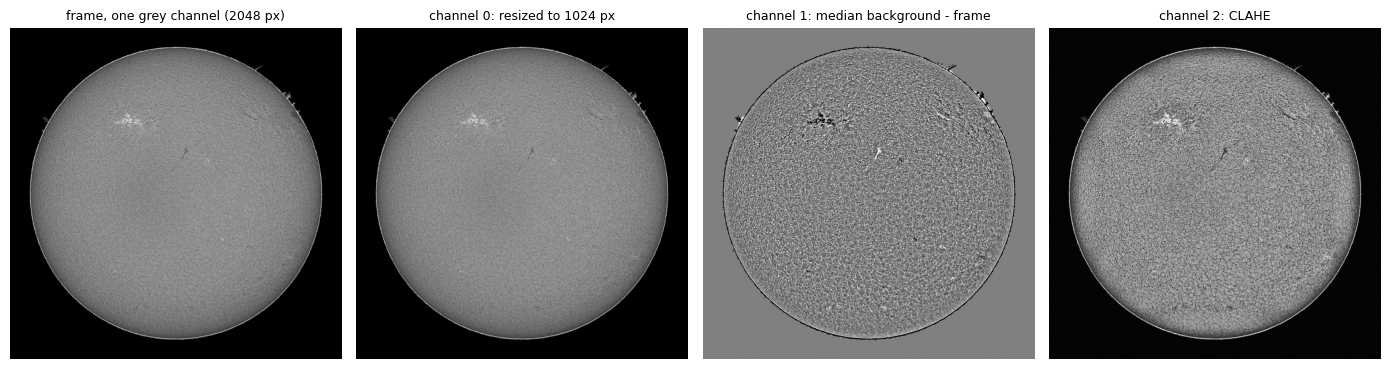

In [4]:
# The network input of one test frame
if files:
    import matplotlib.pyplot as plt
    img = io.read_gray(files[0])               # (2048, 2048) uint8, one channel
    x = preprocess.make_input(img, 1024)       # (3, 1024, 1024) uint8, every channel computed from the grey frame
    print("frame", img.shape, img.dtype, "-> U-Net++ input", x.shape, x.dtype)
    fig, ax = plt.subplots(1, 4, figsize=(14, 3.7))
    titles = ["frame, one grey channel (2048 px)", "channel 0: resized to 1024 px", "channel 1: median background - frame", "channel 2: CLAHE"]
    for a, im, t in zip(ax, [img, x[0], x[1], x[2]], titles):
        a.imshow(im, cmap="gray", vmin=0, vmax=255); a.set_title(t, fontsize=9); a.axis("off")
    fig.tight_layout(); plt.show()
else:
    print(f"test frames not found in {short(test_dir)}: set SOLAR_DATA to see the network input")

## 2. Training (optional), or loading the trained weights

`TRAIN_FROM_SCRATCH = False` (default): every trained model is **downloaded and checked by the next cell**, with no
manual step. The manifest `weights/MANIFEST_final.tsv` lists each file with its size, sha256 and URL on the Hugging Face
Hub. The final model needs 63 files (17.3 GB) on the GPU path. On the CPU path the models of section 3 are not run, so
only the four selector files (39 MB) are downloaded.

`TRAIN_FROM_SCRATCH = True`: the second cell runs the training stages switched on in `TRAIN` (GPU hours each; the others
only print their command), and section 4 refits the selector on the out-of-fold candidates (CPU, about 4 min).

In [5]:
MANIFEST = REPO / "weights" / "MANIFEST_final.tsv"
VARIANTS = {"final": ("final",), "fullfit_a": ("final", "fullfit_a"), "stk": ("stk",)}[PIPELINE]   # column `variants` of the manifest
MEMBER_FILES = [m["checkpoints"] for m in read_yaml(CONFIG)["refiner"].get("members", [])]        # refiner checkpoints of this config


def _keep(r):   # of the full-data refiners (fullfit/), only the six members of this config
    return not r["file"].startswith("fullfit/") or r["file"] in MEMBER_FILES


if RUN_GPU_STAGES:
    W = fetch(MANIFEST, VARIANTS, keep=_keep, strict=True)
else:   # the model outputs are read from the stored files, so only the selector members are needed
    W = fetch(MANIFEST, VARIANTS, keep=_keep, only="nlv/verifier_nlv_" if FINAL else "final/vens/", strict=False)
def wpath(f):
    return W.get(f, WEIGHTS / f)


n_all = sum(1 for r in csv.DictReader(open(MANIFEST), delimiter="\t") if set(VARIANTS) & set(r["variants"].split(",")) and r["role"].startswith("inference") and _keep(r))
_listed = {r["file"] for r in csv.DictReader(open(MANIFEST), delimiter="\t")}
_unlisted = [c for c in MEMBER_FILES if c not in _listed]
print(f"{PIPELINE}: {n_all} weight files in the manifest for the GPU path; refiner members of configs/{CONFIG.name}: {len(MEMBER_FILES)}, "
      f"without a manifest row: {len(_unlisted)}")
assert not (_unlisted and RUN_GPU_STAGES), f"refiner checkpoints without a manifest row: {_unlisted}"

weights: 4 files (0.04 GB) wanted in $SOLAR_WEIGHTS, present and verified 4, missing 0
final: 63 weight files in the manifest for the GPU path; refiner members of configs/final_yellow.yaml: 6, without a manifest row: 0


In [6]:
# Training commands of every model (run when TRAIN_FROM_SCRATCH and the stage is switched on in TRAIN; otherwise printed).
# Training frames always get the output of the fold model that did not see them.
TRAIN = dict(unetpp=False, nnunet=False, swinl1024=False, r50=False, swinl1536=False, cascade=False, rfdetrseg=False,
             own2=False, crops=False, s15f_align=False, s15f_refiner=False, fullfit_refiners=False)
K = "for k in 0 1 2 3 4; do {}; done"
MEMBERS = " ".join(m["tag"] for m in cfg["refiner"].get("members", []))
STEPS = [  # (key, what, command, time measured in the development run)
    ("unetpp", "U-Net++ r34, 5 folds + hold-out", "python -m filament_seg semantic --split split_f$k.json --tag v1f$k  (then --split split_v1.json --tag v1)", "36 min x 6 (RTX 3080 Ti)"),
    ("nnunet", "nnU-Net ResEnc-L 2D, 5 folds", "nnUNetv2_plan_and_preprocess -d 101 -pl nnUNetPlannerResEncL ; " + K.format("nnUNetv2_train 101 2d $k -p nnUNetResEncUNetLPlans -tr nnUNetTrainer_250epochs --npz"), "about 6 h per fold (fold 0 of the submission: 1000 epochs, fold 1: epoch-373 checkpoint)"),
    ("swinl1024", "Mask DINO Swin-L 1024 (candidates)", "filament_seg.maskdino_cands.train(..., arch='swinl', epochs=40)", "about 32 GB GPU memory"),
    ("r50", "Mask DINO R50 seeds 0-2 (votes); seed 3 for g7_m2 (stk)", "filament_seg.maskdino_cands.train(..., arch='r50', seed=s, epochs=40)", "158 min per fold and seed (RTX 3080 Ti)"),
    ("swinl1536", "Mask DINO Swin-L 1536 (refiner planes, S15F features; voter in stk)", "filament_seg.maskdino_cands.train(..., arch='swinl', size=1536, epochs=40)", "-"),
    ("cascade", "Cascade Mask R-CNN R50-FPN 3x (g7_m2; stk only)", K.format("python -m filament_seg.cascade_cands train --fold $k") + " ; python -m filament_seg.cascade_cands test", "about 1.5 h per fold (RTX PRO 6000)"),
    ("rfdetrseg", "RF-DETR-Seg L, res 1008 (refiner planes; g7_m2 in stk)", K.format("python -m filament_seg.rfdetr_cands prep --fold $k && python -m filament_seg.rfdetr_cands train --fold $k && python -m filament_seg.rfdetr_cands infer --fold $k --split val && python -m filament_seg.rfdetr_cands infer --fold $k --split test"), "about 5 h per fold (training) + 22 min per fold (test)"),
    ("own2", "own2 map U-Nets r34 + EffNetV2-S", "python -m filament_seg own-maps --mode oof --train ; --mode testfold", "about 1 GPU hour per family and fold"),
    ("crops", "candidates + refiner crops + NNRP planes", "python -m filament_seg --config configs/stk.yaml crops ; nnrp-planes", "about 1 h (CPU)"),
    ("s15f_align", "S15F: mask_features of 125 reference frames -> PCA16 + ridge (align.npz), OOF feature crops",
     K.format("python -m filament_seg --config configs/stk.yaml s15f-ref --fold $k") + " ; python -m filament_seg --config configs/stk.yaml s15f-fit ; python -m filament_seg --config configs/stk.yaml s15f-train-crops", "about 30 min (RTX 5090)"),
    ("s15f_refiner", "S15F refiner, 5 folds (stk; fold version of the evaluation)", K.format("python -m filament_seg --config configs/stk.yaml residual --fold $k"), "about 19 min per fold (RTX 5090)"),
    ("fullfit_refiners", f"{PIPELINE}: six refiners trained on all 707 frames ({MEMBERS})",
     f"for m in {MEMBERS}; do python -m filament_seg --config configs/{CONFIG.name} residual --fold -1 --member $m; done",
     "1 h 45 min each (six in parallel on one RTX 5090)"),
]
for key, what, c, t in STEPS:
    run = TRAIN_FROM_SCRATCH and TRAIN[key]
    print(f"{'RUN ' if run else '    '}{what:70s} {t}\n        {c}")
    if run:
        if c.startswith(("python", "nnUNet", "for ")):
            subprocess.run(c, shell=True, check=True, cwd=REPO)
        else:
            print("        (Python API: call it with the frames / records of the fold, see the module docstring)")

    U-Net++ r34, 5 folds + hold-out                                        36 min x 6 (RTX 3080 Ti)
        python -m filament_seg semantic --split split_f$k.json --tag v1f$k  (then --split split_v1.json --tag v1)
    nnU-Net ResEnc-L 2D, 5 folds                                           about 6 h per fold (fold 0 of the submission: 1000 epochs, fold 1: epoch-373 checkpoint)
        nnUNetv2_plan_and_preprocess -d 101 -pl nnUNetPlannerResEncL ; for k in 0 1 2 3 4; do nnUNetv2_train 101 2d $k -p nnUNetResEncUNetLPlans -tr nnUNetTrainer_250epochs --npz; done
    Mask DINO Swin-L 1024 (candidates)                                     about 32 GB GPU memory
        filament_seg.maskdino_cands.train(..., arch='swinl', epochs=40)
    Mask DINO R50 seeds 0-2 (votes); seed 3 for g7_m2 (stk)                158 min per fold and seed (RTX 3080 Ti)
        filament_seg.maskdino_cands.train(..., arch='r50', seed=s, epochs=40)
    Mask DINO Swin-L 1536 (refiner planes, S15F features; voter in stk)   

## 3. Inference of the models (GPU; on the CPU path their stored outputs are read)

Each subsection runs one model family on the 180 test frames when `RUN_GPU_STAGES` is true, and otherwise reads the file
that the same stage wrote in the submitted run.

### 3.1 U-Net++ probability map
U-Net++ (`seg_v1.pt`) on the input of section 1 gives the 1024 px probability used by the candidate features and by the
refiner's second plane (fp32, `amp=False`).

In [7]:
if RUN_GPU_STAGES:
    import torch
    from filament_seg import semantic
    dev = torch.device("cuda")
    m = semantic.build_model("resnet34", pretrained=False); m.load_state_dict(torch.load(wpath("seg_v1.pt"), map_location="cpu")); m = m.to(dev)
    V1 = {f.stem: semantic.predict(m, preprocess.make_input(io.read_gray(f), 1024)[None], dev, amp=False)[0].astype(np.float16) for f in files}
    np.save(WORK / "test_names.npy", np.array(test_names)); C["test_names"] = str(WORK / "test_names.npy")
    print("U-Net++ maps", len(V1))
else:
    print("U-Net++: not run (CPU path; the candidate table of 3.2 already holds its features)")

U-Net++: not run (CPU path; the candidate table of 3.2 already holds its features)


### 3.2 Candidates: nnU-Net components and Mask DINO Swin-L 1024 instances
nnU-Net ResEnc-L 2D (one model per fold, mirroring TTA): connected components of its map at 0.3 / 0.4, area >= 50.
Mask DINO Swin-L 1024: instances with score >= 0.05 and >= 30 px. `final` / `fullfit_a`: the candidates of frame i come
from fold model i % 5, so each fold model predicts its 36 frames only (`ALL_FOLDS = False`). `stk` also needs every
Swin-L 1024 fold model on all 180 frames (`ALL_FOLDS = True`).

In [8]:
def all_folds(model_paths, load, predict, every_frame=True):
    """{k: {stem: [(score, RLE)]}}: every fold model on every test frame (g7_m2 calibration, refiner planes and S15F use all
    of them). every_frame=False: fold model k only predicts the frames i with i % 5 == k (all that candidates and votes read)."""
    out = {}
    for k, p in enumerate(model_paths):
        mdl = load(p); out[k] = {f.stem: predict(mdl, io.read_gray(f)) for i, f in enumerate(files) if every_frame or i % 5 == k}; del mdl
    return out


def dump_folds(P, name):
    for k, d in P.items():
        pickle.dump(d, open(WORK / f"{name}_f{k}.pkl", "wb"))
    return str(WORK / f"{name}_f{{k}}.pkl")


if RUN_GPU_STAGES:
    assert ALL_FOLDS or "evo" not in C, "stk needs ALL_FOLDS = True (g7_m2 reads every fold model on every frame)"
    from filament_seg import maskdino_cands, nnunet_cands
    import cv2
    nn_in = WORK / "nn_in"; nn_in.mkdir(exist_ok=True)
    for f in files:
        cv2.imwrite(str(nn_in / f"{f.stem}_0000.png"), io.read_gray(f))
    nn_rows = [r for r in csv.DictReader(open(MANIFEST), delimiter="\t") if r["file"].endswith("checkpoint_final.pth")]
    for k in range(5):
        ck = wpath([r["file"] for r in nn_rows if f"fold_{k}/" in r["file"]][0])
        nnunet_cands.predict_maps(ck.parent.parent, k, nn_in, WORK / "nnunet_test_maps" / f"f{k}", checkpoint="checkpoint_final.pth")
    C["test_nnmaps"] = str(WORK / "nnunet_test_maps" / "f{k}")
    SWL = all_folds([wpath(f"nlv/maskdino_swinl_f{k}.pt") for k in range(5)],
                    lambda p: maskdino_cands.load(MDROOT, p, "cuda", arch="swinl"), maskdino_cands.predict, every_frame=ALL_FOLDS)
    if "evo" in C:   # stk: g7_m2 duplicate-query column
        C["evo"]["test_swinl_queries"] = dump_folds(SWL, "maskdino_test_swinl")
    rows, rles = [], {}
    for i, f in enumerate(files):
        n = f.stem
        r, rl = nlv.candidates_image(n, V1[n].astype(np.float32), io.read_gray(f), nnunet_cands.load_map(WORK / "nnunet_test_maps" / f"f{i % 5}", n), SWL[i % 5][n], [], cfg)
        rows += r; rles[n] = rl
    pd.DataFrame(rows).to_parquet(WORK / "test_cands.parquet"); pickle.dump(rles, open(WORK / "test_rles.pkl", "wb"))
    C.update(test_cands=str(WORK / "test_cands.parquet"), test_rles=str(WORK / "test_rles.pkl"))
T0 = pd.read_parquet(C["test_cands"]); TR = pickle.load(open(C["test_rles"], "rb"))
# column `source`: 'yolo' = Mask DINO Swin-L instance, 'v1_b03' / 'v1_b04' = nnU-Net component at 0.3 / 0.4 (names kept from earlier detectors)
print(f"{len(T0)} candidates on {T0.image.nunique()} frames; sources {T0.source.value_counts().to_dict()}")

10189 candidates on 180 frames; sources {'yolo': 6641, 'v1_b03': 1784, 'v1_b04': 1764}


### 3.3 Detectors that are not candidate sources (votes, refiner planes)
| model | used by | forward passes per test frame |
|---|---|---|
| Mask DINO R50 seeds 0 / 1 / 2 | votes (frame i: fold i % 5); g7_m2 family in `stk` (all folds) | 3 (`final` / `fullfit_a`) / 3 x 5 (`stk`) |
| Mask DINO R50 seed 3 | g7_m2 family (`stk` only) | 5 |
| Mask DINO Swin-L 1536 | refiner best-match plane, S15F features; 4th voter and g7_m2 family in `stk` | 5 |
| Cascade Mask R-CNN R50-FPN | g7_m2 family (`stk` only) | 5 |
| RF-DETR-Seg L | refiner best-match plane; g7_m2 family in `stk` | 5 |

A vote tells the selector whether an independent detector found the same filament (best IoU, score, number of agreeing seeds).

In [9]:
R50_SEEDS = [0, 1, 2] if FINAL else [0, 1, 2, 3]
EVO = "evo" in C   # g7_m2 columns (stk); the final model has none
if RUN_GPU_STAGES:
    r50 = lambda s, k: wpath(f"nlv/maskdino_r50_s{s}_f{k}.pt") if s < 3 else wpath(f"final/maskdino_r50_s3_f{k}.pt")  # noqa: E731
    for s in R50_SEEDS:
        P = all_folds([r50(s, k) for k in range(5)], lambda p: maskdino_cands.load(MDROOT, p, "cuda", arch="r50"), maskdino_cands.predict,
                      every_frame=ALL_FOLDS)
        pat = dump_folds(P, f"maskdino_test_s{s}")
        if EVO:
            C["evo"]["test_preds"][f"r50_s{s}"] = pat
        if s < 3:
            C["test_voters"][f"s{s}"] = pat
    P = all_folds([wpath(f"final/maskdino_swinl1536_f{k}.pt") for k in range(5)], lambda p: maskdino_cands.load(MDROOT, p, "cuda", arch="swinl"),
                  lambda m, img: maskdino_cands.predict(m, img, size=1536))
    C["refplanes"]["test"]["swinl1536"] = pat = dump_folds(P, "maskdino_test_swinl1536")
    if EVO:
        C["test_voters"]["sl"] = C["evo"]["test_preds"]["swinl1536"] = pat
    from filament_seg import cascade_cands, rfdetr_cands
    sc, sr = cascade_cands.settings(cfg), rfdetr_cands.settings(cfg)
    if EVO:
        C["evo"]["test_preds"]["cascade"] = dump_folds(all_folds([wpath(f"final/cmrcnn_r50fpn_f{k}.pt") for k in range(5)],
                                                                lambda p: cascade_cands.load(p, sc), lambda m, img: cascade_cands.predict_image(m, img, sc)), "cmrcnn_test")
    C["refplanes"]["test"]["rfdetrseg"] = pat = dump_folds(
        all_folds([wpath(f"final/rfdetrseg_l_f{k}.pth") for k in range(5)], lambda p: rfdetr_cands.load(p, sr),
                  lambda m, img: rfdetr_cands.predict_frame(m, img, sr)), "rfdetrseg_test")
    if EVO:
        C["evo"]["test_preds"]["rfdetrseg"] = pat
VOT, VF = (votes.VOTERS_STK, votes.VFEATS_STK) if nlv.is_stk(C) else (votes.VOTERS, votes.VFEATS)
P = {k: [pickle.load(open(os.path.expandvars(C["test_voters"][k]).format(k=f), "rb")) for f in range(5)] for k in VOT}
VT = votes.test_votes(T0, TR, test_names, P, VOT)
print(f"vote features of {len(VT)} candidates (mean and max):")
print(VT[VF].describe().loc[["mean", "max"]].round(3).to_string())

vote features of 10189 candidates (mean and max):
      v_s0_iou  v_s0_sc  v_s1_iou  v_s1_sc  v_s2_iou  v_s2_sc  v_agree2  v_agree3
mean     0.647    0.335     0.649    0.340     0.648    0.341     1.563     2.343
max      0.958    0.966     0.957    0.962     0.959    0.965     2.000     3.000


### 3.4 g7_m2 agreement / shape columns (`stk` only; CPU, 1.5 min)
Not part of the final model. Family agreement weighted per test group (no labels), Swin-L 1024 duplicate queries,
containment in an nnU-Net component, nnU-Net map beyond the skeleton tips. Recomputed from the detector outputs of 3.3;
must equal the stored columns of the submitted run.

In [10]:
if EVO:
    E = evofeats.test_features(C)
    ref = pd.read_parquet(C["evo"]["test"]).merge(E, on=["image", "idx"], suffixes=("_ref", ""))
    diff = max(float(np.nanmax(np.abs(ref[c + "_ref"] - ref[c]))) for c in evofeats.COLS)
    print(f"g7_m2 test columns: {len(E)} rows, max abs diff vs the submitted table {diff}")
    E.to_parquet(WORK / "g7_m2_test.parquet"); C["evo"]["test"] = str(WORK / "g7_m2_test.parquet")
else:
    print("g7_m2: not used by", PIPELINE)

g7_m2: not used by final


### 3.5 own2 probability maps (14 selector features per candidate)
Two segmentation networks of ours (U-Net r34 and EfficientNetV2-S), 8 flips / rotations each, one map per fold model.
The selector is applied once per fold map and the five scores are averaged (inside `final-cpu`, section 4).

In [11]:
if RUN_GPU_STAGES:
    from filament_seg import ownmap
    imgs = {f.stem: io.read_gray(f) for f in files}
    for k in range(5):
        for fam in ("r34", "eff"):
            mdl = ownmap.load_model(wpath(f"nlv/own2_{fam}_f{k}.pt"), fam, torch.device("cuda"))
            ownmap.write_maps(mdl, fam, imgs, test_names, WORK / "own2_test" / f"f{k}", torch.device("cuda"))
    C["test_maps"] = str(WORK / "own2_test" / "f{k}")
print("own2 maps:", short(C["test_maps"]), "x 5 folds,", len(list(Path(C["test_maps"].format(k=0)).glob("*.png"))), "files in fold 0")

own2 maps: $SOLAR_ROOT/outputs/pm/own2/f{k} x 5 folds, 360 files in fold 0


### 3.6 Refiner: six members trained on all 707 frames (NNRP and S15F, three seeds each)
Members = `refiner.members` of the config. `final`: seeds 16 / 17 / 18 (`fullfit/refiner_FF{NNRP,S15F}x{16,17,18}_f-1.pt`);
`fullfit_a`: no seed / 11 / 12; `stk`: one S15F refiner per fold. A member trained on all frames takes the place of each
fold model in step 3 below: it reads the planes / features of fold k for k = 0..4 and the five probabilities are averaged.
The six members are averaged with equal weights (NNRP members use the planes only).
1. Planes: 4 base crops (frame, U-Net++, candidate, partner), nnU-Net map of fold k, best-matching Swin-L 1536 /
   RF-DETR-Seg mask of the fold-k detectors (IoU >= 0.3), 2 source planes (`refplanes.nnrp_planes`).
2. Features (S15F members): fold-k Swin-L 1536 pixel-decoder `mask_features` (stride 4, 256 channels) -> 16 channels shared
   by the five fold models (`s15f_align.npz`: PCA of 125 reference frames + one ridge map per fold model, no labels) ->
   64 x 64 crop of each candidate's refiner window.
3. Refiner on the planes / features of fold k, flip TTA x 4, mean of the five probabilities, paste-back into the frame.

On a GTX 1080 Ti this stage took 58 min for the 180 frames (10,189 candidates) and reproduced the stored masks byte for
byte (README, "Final model"). The masks printed below are before C0.

In [12]:
if RUN_GPU_STAGES:
    from filament_seg import s15f, refiner
    al = dict(np.load(wpath("final/s15f_align.npz")))
    c = cfg["refiner"]; T0r = T0.reset_index(drop=True)
    BOX = s15f.test_boxes(T0r, c["crop_scale"], c["crop_min_side"])
    raws = {f.stem: io.read_gray(f) for f in files}
    FT = {}
    for k in range(5):   # fold-k Swin-L 1536 -> mask_features -> common 16 channels (align.npz) -> 64 x 64 crops
        mdl, box = s15f.load_model(MDROOT, wpath(f"final/maskdino_swinl1536_f{k}.pt"), "cuda")
        FT[k] = s15f.test_crops(mdl, box, al, k, T0r, BOX, raws.__getitem__); del mdl
    cfg["nlv"].update({kk: v for kk, v in C.items() if isinstance(v, (str, dict))})   # planes read the detector outputs of this run
    if FINAL:   # refiner.members of the config: one full-data checkpoint per member, applied to the five fold-k inputs
        members = [dict(tag=m["tag"], full=True, checkpoints=[wpath(m["checkpoints"])] * 5, feats=FT.__getitem__ if m.get("test_feats") else None)
                   for m in cfg["refiner"]["members"]]
    else:
        members = [dict(tag="S15F", checkpoints=[wpath(f"final/refiner_S15F_f{k}.pt") for k in range(5)], feats=FT.__getitem__)]
    REFD = nlv.refine_test(cfg, T0r, TR, {n: V1[n].astype(np.float32) for n in raws}, raws, members, "cuda")
    pickle.dump(REFD, open(WORK / "refiner_test_rles.pkl", "wb")); C["refiner_rles"] = str(WORK / "refiner_test_rles.pkl")
REF = pickle.load(open(C["refiner_rles"], "rb"))
print(f"{PIPELINE}: refined masks for {len(REF)} frames, {sum(len(v) for v in REF.values())} candidates")

final: refined masks for 180 frames, 10189 candidates


## 4. Post-processing: selector scores, C0, decode -> submission.csv (CPU)

One command, `python -m filament_seg --config <config> final-cpu`:
1. **Selector.** V-ENS scores every candidate (`final` / `fullfit_a`: four members, 70 features, files `nlv/verifier_nlv_*`;
   `stk`: five seeds, 80 features). It is a trained model, but it runs on the CPU in the same command as the rules below, so
   it is shown here. With `TRAIN_FROM_SCRATCH` the members are refitted on the 39,314 out-of-fold candidates of the 707
   training frames instead of loaded.
2. **C0.** A Swin-L candidate whose refined mask is below 0.6 x its unrefined area keeps the unrefined mask.
3. **Decode.** Candidates with `y_hat` > tau (0.25) are placed in decreasing `y_hat`. In `final`, 0.10 is added to the
   `y_hat` of the Swin-L candidates for this order only (`decode.order_bonus`); the threshold test uses the unchanged score.
   A candidate whose IoU with an already accepted one is above 0.3 is dropped (mask NMS). Pixels that an earlier mask
   already holds are removed from a later one, and a mask that keeps less than half of its pixels is dropped, so the
   output has no overlaps.

In the stored run this cell took 195 s (macOS arm64, 2 CPU threads; most of it: the own2 map features of 5 fold maps x
10,189 candidates). The command runs
in a subprocess, because CatBoost / XGBoost must not share a process with torch on macOS.

In [13]:
import yaml
cfg_run = read_yaml(CONFIG)   # the config with its includes, plus the paths this notebook changed (outputs of a GPU run, rebuilt annotations)
cfg_run["nlv"].update({k: v for k, v in C.items() if isinstance(v, (str, dict))})
run_cfg = WORK / "final_run.yaml"; yaml.safe_dump(cfg_run, open(run_cfg, "w"), sort_keys=False)
probe = "verifier_nlv_et.joblib" if FINAL else "seed4/verifier_nlv_et.joblib"
dirs = [WEIGHTS / ("nlv" if FINAL else "final/vens")] + ([Path(C["vens_weights"])] if C.get("vens_weights") else [])
VENS = None if TRAIN_FROM_SCRATCH else next((d for d in dirs if (d / probe).exists()), None)   # the download of section 2 first
OUT = WORK / "submission.csv"
cmd = [sys.executable, "-m", "filament_seg", "--config", str(run_cfg), "final-cpu", "--out", str(OUT)]
if VENS is not None:
    cmd += ["--load-weights", str(VENS)]; print("selector members: loaded from", short(VENS))
elif Path(C["train_cands"]).exists():
    cmd += ["--save-weights", str(WORK / "vens")]; print("selector members: refitted on the out-of-fold candidates (4 / 8 min)")
else:
    raise FileNotFoundError(f"selector members not found in {[short(d) for d in dirs]} (section 2) and no training table to refit them ({short(C['train_cands'])})")
t = time.time(); r = subprocess.run(cmd, capture_output=True, text=True, env={**os.environ, "OMP_NUM_THREADS": THREADS})
assert r.returncode == 0, r.stderr[-2000:]
res = json.loads(r.stdout[r.stdout.index("{"):])
print(json.dumps({k: (Path(v).name if k in ("csv", "yhat") else v) for k, v in res.items()}, indent=1)); print(f"{time.time() - t:.0f} s")

selector members: loaded from $SOLAR_WEIGHTS/nlv


{
 "yhat": "submission.yhat.parquet",
 "yhat_max_abs_diff_vs_submitted": 0.0,
 "c0_replaced": 914,
 "csv": "submission.csv",
 "md5": "540c886326cff3320dd341c0dedd2cd1",
 "rows": 1209,
 "minutes": 3.2
}
195 s


In [14]:
# CSV check (the checks of the Kaggle server) and comparison with the submitted CSV
chk = submission.validate(OUT, set(test_names)); print(chk)
assert all(chk[k] for k in ("header_ok", "no_quotes", "ids_ok", "stems_in_test", "no_overlap"))
REF_MD5 = {"final": "540c886326cff3320dd341c0dedd2cd1", "fullfit_a": "31e0708424a321eb19d996a2a2868dcf", "stk": "a2089e625c58f5c7675dedd249a5d35a"}[PIPELINE]
rows = sum(1 for _ in open(OUT)) - 1
frames = pd.read_csv(OUT).filament_id.str.rsplit("_", n=1).str[0].nunique()
print(f"{OUT.name}: {rows} filaments on {frames} frames, md5 {res['md5']}")
print(f"byte-identical to the submitted CSV of {PIPELINE} (md5 {REF_MD5}):", res["md5"] == REF_MD5)
if not RUN_GPU_STAGES and VENS is not None:
    # stored model outputs + loaded selector: the CSV must be the submitted one. A GPU rerun may differ in a few masks, and a
    # refitted selector may differ slightly on another machine (README, "Reproducibility notes").
    assert res["md5"] == REF_MD5

{'header_ok': True, 'no_quotes': True, 'ids_ok': True, 'stems_in_test': True, 'no_overlap': True, 'rows': 1209, 'images': 178}
submission.csv: 1209 filaments on 178 frames, md5 540c886326cff3320dd341c0dedd2cd1
byte-identical to the submitted CSV of final (md5 540c886326cff3320dd341c0dedd2cd1): True


## 5. Evaluation on the training frames (out-of-fold)

The test labels are hidden, so the model is evaluated on the 707 training frames, each one predicted by models that did
not see it: out-of-fold selector scores (nested 5-fold fit), out-of-fold masks of the fold refiners, C0, and the same
decode as on the test set. The refiners of the final model were trained on all frames and have no held-out frames, so the
masks here come from their **fold version** (same recipe, five fold models per member, seeds none / 11 / 12). The
numbers below are therefore those of the fold version with the decode of the selected `PIPELINE`.
Ground truth = each annotator record separately, as in the organisers' self-evaluation notebook.

a. **PQ** (`nlv.oof_eval`): `rec_pq` = against the records as they are. `sim_pq` = each ground-truth filament is kept
   with probability 0.77 (mean of 5 draws); this keep rate was calibrated on the public leaderboard scores of our
   earlier submissions (README).

b. **The quantities of the scoring rubric** (`metrics.rubric`), for the model and, as a reference, for one annotator
   against another on the frames with two or three records:

| row | meaning |
|---|---|
| `PQ`, `SQ`, `RQ`, `TP`, `FP`, `FN` | panoptic quality; a prediction and a ground-truth mask match when IoU > 0.5 |
| `dice_mean` | mean Dice per record: torchmetrics `DiceScore` on the union of the predictions vs the union of the ground truth |
| `pair_iou_mean`, `pair_dice_mean` | mean IoU / Dice over all overlapping (ground truth, prediction) pairs |
| `gt_missed`, `pred_unmatched` | share of ground-truth masks / predictions that overlap nothing |
| `gt_one_to_many` | share of ground-truth masks overlapped by two or more predictions (fragmentation) |
| `pred_many_to_one` | share of predictions that overlap two or more ground-truth masks (over-merging) |

In [15]:
OOF_KEYS = ["gt_rles", "oof_yhat", "train_cands", "train_rles"] + [f"oof_refiner_rles:{k}" for k in range(5)]
oof_missing = [short(C[k.split(":")[0]].format(k=k[-1])) for k in OOF_KEYS if not Path(C[k.split(":")[0]].format(k=k[-1])).exists()]
HAS_OOF = not oof_missing
if HAS_OOF:
    t = time.time()
    r = subprocess.run([sys.executable, "-m", "filament_seg", "--config", str(run_cfg), "oof-eval"], capture_output=True, text=True,
                       env={**os.environ, "OMP_NUM_THREADS": THREADS})
    assert r.returncode == 0, r.stderr[-2000:]
    ev = json.loads(r.stdout[r.stdout.index("{"):]); print(ev, f"({time.time() - t:.0f} s)")
    EXP = {"final": (0.4759, 0.4144), "fullfit_a": (0.4758, 0.4142), "stk": (0.4767, 0.4171)}[PIPELINE]
    print(f"as in the development log, rec / sim {EXP}:", (ev["rec_pq"], ev["sim_pq"]) == EXP)
else:
    print("section 5 skipped, these tables were not found (the annotations need SOLAR_DATA/train):\n  " + "\n  ".join(oof_missing))

{'tau': 0.25, 'frames': 707, 'rec_pq': 0.4759, 'sim_pq': 0.4144} (49 s)
as in the development log, rec / sim (0.4759, 0.4144): True


In [16]:
# b. rubric quantities: decode the out-of-fold candidates exactly as nlv.oof_eval does, then metrics.rubric
from itertools import permutations
if HAS_OOF:
    t = time.time()
    gt = pickle.load(open(C["gt_rles"], "rb"))
    Y = pd.read_parquet(C["oof_yhat"]).rename(columns={"yhat_ens": "yhat"})
    src = pd.read_parquet(C["train_cands"], columns=["image", "idx", "source"])
    kn = nlv.decode_knobs(cfg)   # order_bonus etc. of the config
    if kn["order_bonus"]:
        Y = nlv.with_source(Y, src)
    RO = {}
    for k in range(5):
        RO.update(pickle.load(open(C["oof_refiner_rles"].format(k=k), "rb")))
    RO, _ = nlv.apply_c0(src, RO, pickle.load(open(C["train_rles"], "rb")), cfg["refiner"]["c0_ratio"])
    d = cfg["decode"]; G = {n: g for n, g in Y.groupby("image")}
    names = sorted(n for n in gt if n in G)
    names = names if EVAL_FRAMES is None else sorted(np.random.default_rng(0).choice(names, EVAL_FRAMES, replace=False))
    PR = {n: nlv.decode_image(G[n], RO[n], d["tau"], d["nms_iou"], d["keep_frac"], **kn) for n in names}
    model_res, model_tm, model_iou = metrics.rubric([(rec, PR[n]) for n in names for rec in gt[n]])
    multi = [n for n in names if len(gt[n]) > 1]
    human_res, human_tm, human_iou = metrics.rubric([(gt[n][a], gt[n][b]) for n in multi for a, b in permutations(range(len(gt[n])), 2)])
    model_res["pairs"], human_res["pairs"] = len(model_iou), len(human_iou)
    show = lambda k, v: str(int(v)) if k in ("TP", "FP", "FN", "dice_nan_records", "pairs") else f"{v:.4f}"   # noqa: E731
    tab = pd.DataFrame({name: {k: show(k, v) for k, v in res_.items()} for name, res_ in (("model (out-of-fold)", model_res), ("annotator vs annotator", human_res))})
    print(f"model: {len(names)} frames, {sum(len(gt[n]) for n in names)} annotator records, {sum(len(PR[n]) for n in names)} predicted filaments; "
          f"annotators: {len(multi)} frames with two or three records ({time.time() - t:.0f} s)")
    print(tab.to_string())

model: 707 frames, 1154 annotator records, 4662 predicted filaments; annotators: 296 frames with two or three records (68 s)
                 model (out-of-fold) annotator vs annotator
PQ                            0.4759                 0.3399
SQ                            0.6884                 0.6337
RQ                            0.6913                 0.5364
TP                              5464                   4292
FP                              2144                   3709
FN                              2735                   3709
dice_mean                     0.6744                 0.6137
dice_median                   0.7083                 0.6409
dice_nan_records                   0                      0
pair_iou_mean                 0.6161                 0.5174
pair_dice_mean                0.7451                 0.6606
gt_missed                     0.1943                 0.1775
gt_one_to_many                0.0228                 0.0316
pred_unmatched                0.129

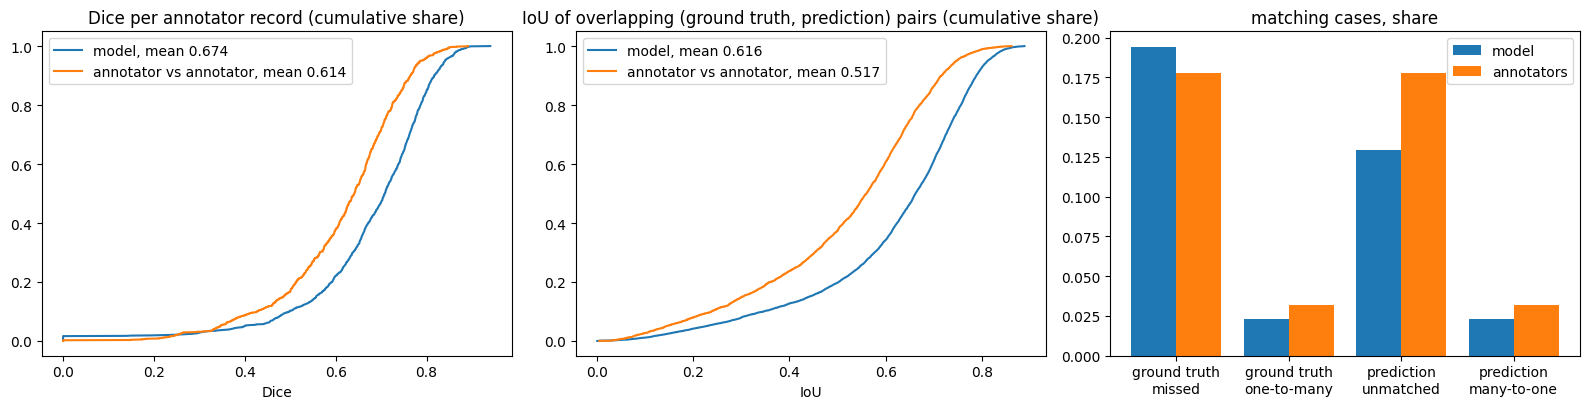

In [17]:
if HAS_OOF:
    import matplotlib.pyplot as plt
    fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
    for lab, tm_, iou_ in (("model", model_tm, model_iou), ("annotator vs annotator", human_tm, human_iou)):
        v = np.sort(tm_[~np.isnan(tm_)]); ax[0].plot(v, np.linspace(0, 1, len(v)), label=f"{lab}, mean {v.mean():.3f}")
        v = np.sort(iou_); ax[1].plot(v, np.linspace(0, 1, len(v)), label=f"{lab}, mean {v.mean():.3f}")
    ax[0].set(title="Dice per annotator record (cumulative share)", xlabel="Dice"); ax[0].legend()
    ax[1].set(title="IoU of overlapping (ground truth, prediction) pairs (cumulative share)", xlabel="IoU"); ax[1].legend()
    keys = ["gt_missed", "gt_one_to_many", "pred_unmatched", "pred_many_to_one"]; x = np.arange(len(keys))
    ax[2].bar(x - 0.2, [model_res[k] for k in keys], 0.4, label="model"); ax[2].bar(x + 0.2, [human_res[k] for k in keys], 0.4, label="annotators")
    ax[2].set_xticks(x, ["ground truth\nmissed", "ground truth\none-to-many", "prediction\nunmatched", "prediction\nmany-to-one"])
    ax[2].set(title="matching cases, share"); ax[2].legend()
    fig.tight_layout(); plt.show()